In [14]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/aggressive_behavior.csv
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/aggressive/3.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/aggressive/1.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/aggressive/4.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/aggressive/0.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/aggressive/2.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/non_aggressive/5.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/non_aggressive/3.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/non_aggressive/1.mp4
/kaggle/input/datasets/trainingdatapro/aggressive-behavior-v

## Dataset and Sequence Analysis
* Dataset - Violence Detection Video Classification
* Although we can only take aggressive clips but I have also taken non-aggressive clips so that we can consilidate our analysis

In [15]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# DATASET PATHS
# ============================================================

DATASET_ROOT = Path(
    "/kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files"
)

AGGRESSIVE_DIR = DATASET_ROOT / "aggressive"
NON_AGGRESSIVE_DIR = DATASET_ROOT / "non_aggressive"

print("Aggressive directory:", AGGRESSIVE_DIR)
print("Non-aggressive directory:", NON_AGGRESSIVE_DIR)

print("\nAggressive files:")
for f in sorted(AGGRESSIVE_DIR.iterdir()):
    print(f.name)

print("\nNon-aggressive files:")
for f in sorted(NON_AGGRESSIVE_DIR.iterdir()):
    print(f.name)

Aggressive directory: /kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/aggressive
Non-aggressive directory: /kaggle/input/datasets/trainingdatapro/aggressive-behavior-video-classification/files/non_aggressive

Aggressive files:
0.mp4
1.mp4
2.mp4
3.mp4
4.mp4

Non-aggressive files:
0.mp4
1.mp4
2.mp4
3.mp4
4.mp4
5.mp4


In [16]:
# ============================================================
# COLLECT VIDEO FILES
# ============================================================

VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv", ".webm"}

def get_video_files(directory):
    return sorted([
        f for f in directory.iterdir()
        if f.is_file() and f.suffix.lower() in VIDEO_EXTENSIONS
    ])


aggressive_videos = get_video_files(AGGRESSIVE_DIR)
non_aggressive_videos = get_video_files(NON_AGGRESSIVE_DIR)

print("Number of aggressive videos:", len(aggressive_videos))
print("Number of non-aggressive videos:", len(non_aggressive_videos))
print("Total videos:", len(aggressive_videos) + len(non_aggressive_videos))

Number of aggressive videos: 5
Number of non-aggressive videos: 6
Total videos: 11


In [17]:
# VIDEO METADATA

def get_video_metadata(video_path):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return {
            "file": video_path.name,
            "readable": False
        }

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    duration = frame_count / fps if fps > 0 else 0

    cap.release()

    return {
        "file": video_path.name,
        "path": str(video_path),
        "fps": fps,
        "frame_count": frame_count,
        "duration_sec": duration,
        "width": width,
        "height": height,
        "resolution": f"{width}x{height}",
        "readable": True
    }


records = []

for video_path in aggressive_videos:
    metadata = get_video_metadata(video_path)
    metadata["class"] = "aggressive"
    records.append(metadata)

for video_path in non_aggressive_videos:
    metadata = get_video_metadata(video_path)
    metadata["class"] = "non_aggressive"
    records.append(metadata)


video_df = pd.DataFrame(records)

video_df

,file,path,fps,frame_count,duration_sec,width,height,resolution,readable,class
0,0.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,60.032406,741,12.343333,1920,1080,1920x1080,True,aggressive
1,1.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,60.240964,365,6.059000,1920,1080,1920x1080,True,aggressive
2,2.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,60.660445,169,2.786000,1920,1080,1920x1080,True,aggressive
3,3.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,60.063794,1111,18.497000,1920,1080,1920x1080,True,aggressive
4,4.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,60.058799,1287,21.429000,1920,1080,1920x1080,True,aggressive
5,0.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,29.970030,96,3.203200,1280,720,1280x720,True,non_aggressive
6,1.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,30.000000,330,11.000000,960,720,960x720,True,non_aggressive
7,2.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,25.000000,78,3.120000,1280,720,1280x720,True,non_aggressive
8,3.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,29.970030,54,1.801800,1174,660,1174x660,True,non_aggressive
9,4.mp4,/kaggle/input/datasets/trainingdatapro/aggress...,30.000000,250,8.333333,1280,720,1280x720,True,non_aggressive


In [ ]:
# ============================================================
# SUMMARY STATISTICS
# ============================================================

summary = video_df.groupby("class").agg(
    videos=("file", "count"),
    avg_frames=("frame_count", "mean"),
    min_frames=("frame_count", "min"),
    max_frames=("frame_count", "max"),
    avg_duration=("duration_sec", "mean"),
    min_duration=("duration_sec", "min"),
    max_duration=("duration_sec", "max"),
    avg_fps=("fps", "mean")
)

summary

### Verify frame ordering and sequence integrity
* The video opens successfully
* Frames can be decoded sequentially.
* There are no unexpected read failures
* The actual decoded frame count is consistent with the metadata

In [ ]:
# ============================================================
# SEQUENCE INTEGRITY CHECK
# ============================================================

def verify_video_sequence(video_path):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        return {
            "file": video_path.name,
            "readable": False,
            "metadata_frames": 0,
            "decoded_frames": 0,
            "read_failures": 1,
            "integrity": False
        }

    metadata_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    decoded_frames = 0
    read_failures = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        if frame is None:
            read_failures += 1
            continue

        decoded_frames += 1

    cap.release()

    # Allow a small discrepancy because video metadata can
    # occasionally differ from the number of decodable frames.
    frame_difference = abs(
        metadata_frames - decoded_frames
    )

    integrity = (
        decoded_frames > 0
        and read_failures == 0
        and frame_difference <= 1
    )

    return {
        "file": video_path.name,
        "metadata_frames": metadata_frames,
        "decoded_frames": decoded_frames,
        "read_failures": read_failures,
        "frame_difference": frame_difference,
        "integrity": integrity
    }


integrity_records = []

for video_path in aggressive_videos + non_aggressive_videos:
    integrity_records.append(
        verify_video_sequence(video_path)
    )

integrity_df = pd.DataFrame(integrity_records)

display(integrity_df)

### observation - There are no failures here 

## Read frames from a video

In [23]:
# UNIFORM FRAME SAMPLING

def sample_frames(video_path, num_frames=8):

    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        return [], []

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    frames = []
    actual_indices = []

    for idx in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(idx)
        )

        ret, frame = cap.read()

        if ret:
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frames.append(frame)
            actual_indices.append(idx)

    cap.release()

    return frames, actual_indices

### Temporal frame-strip visualization

In [21]:
# ============================================================
# FRAME STRIP
# ============================================================

def plot_temporal_strip(
    video_path,
    num_frames=3,
    figsize=(18, 4)
):

    frames, indices = sample_frames(
        video_path,
        num_frames=num_frames
    )

    if len(frames) == 0:
        print("Could not read frames.")
        return

    fig, axes = plt.subplots(
        1,
        len(frames),
        figsize=figsize
    )

    axes = np.atleast_1d(axes)

    for ax, frame, idx in zip(
        axes,
        frames,
        indices
    ):

        ax.imshow(frame)

        ax.set_title(
            f"Frame {idx}"
        )

        ax.axis("off")

    plt.suptitle(
        f"{video_path.parent.name} — {video_path.name}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

Class: aggressive
Video: 0.mp4


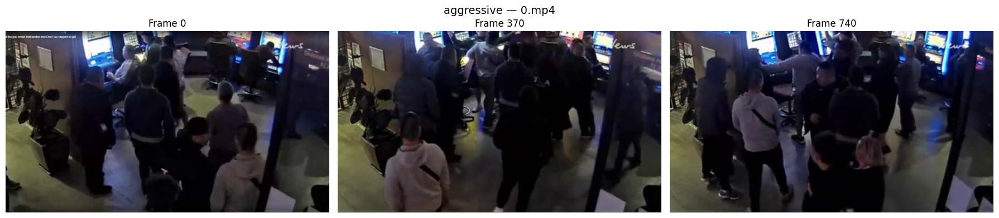

Class: aggressive
Video: 1.mp4


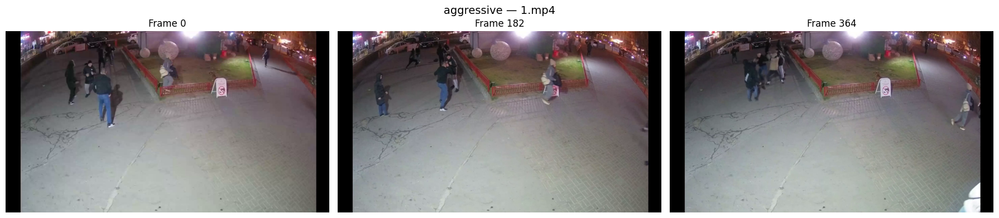

Class: aggressive
Video: 2.mp4


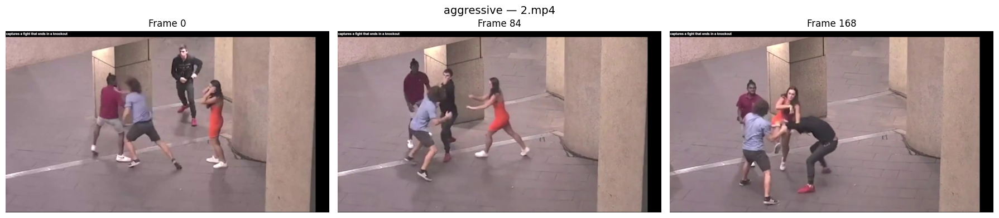

Class: aggressive
Video: 3.mp4


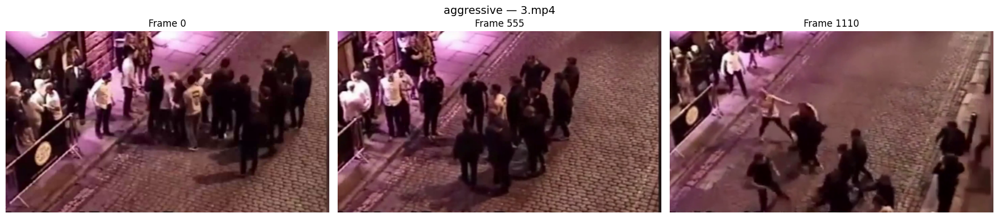

Class: aggressive
Video: 4.mp4


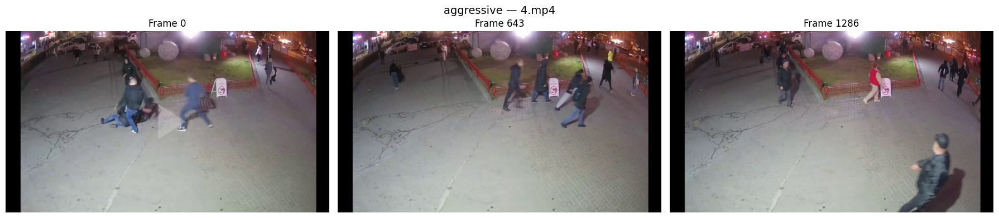

Class: non_aggressive
Video: 0.mp4


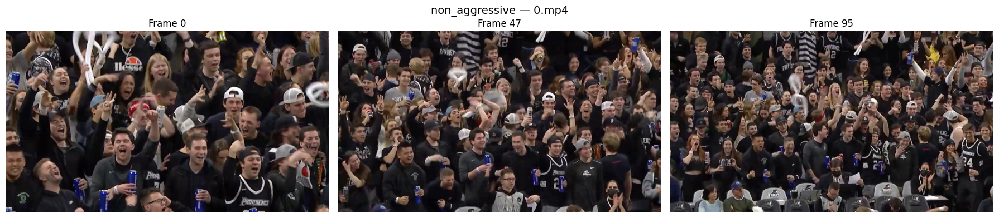

Class: non_aggressive
Video: 1.mp4


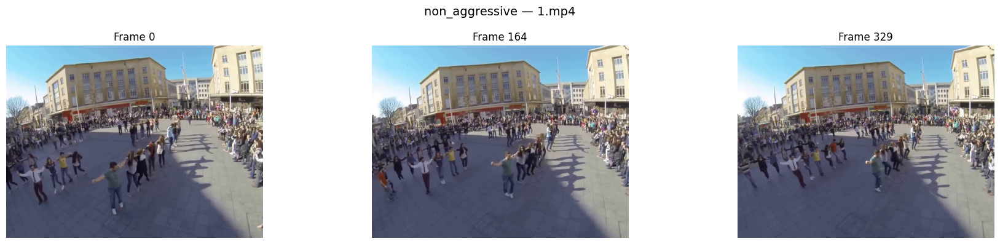

Class: non_aggressive
Video: 2.mp4


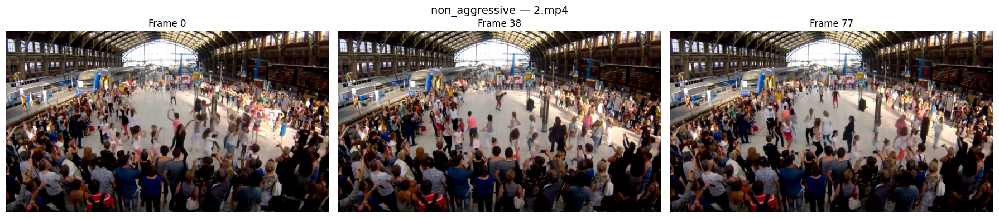

Class: non_aggressive
Video: 3.mp4


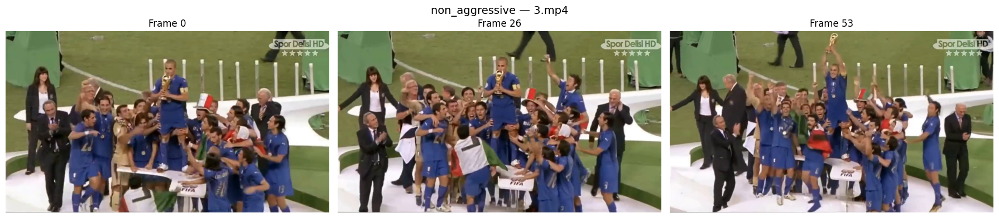

Class: non_aggressive
Video: 4.mp4


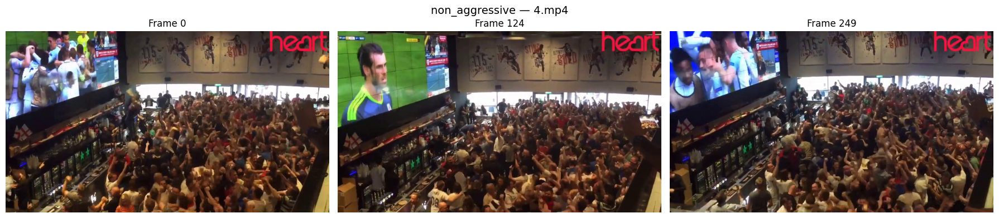

Class: non_aggressive
Video: 5.mp4


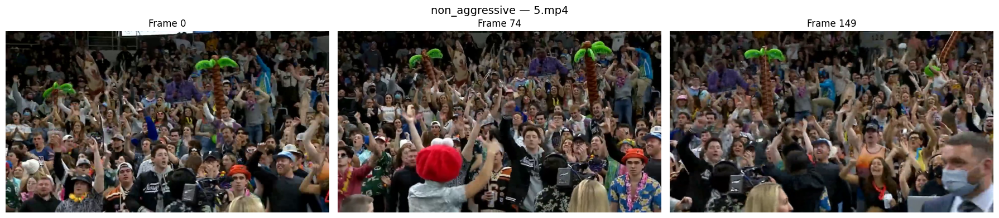

In [24]:
# ============================================================
# DISPLAY ALL SEQUENCES
# ============================================================

all_videos = (
    [(v, "aggressive") for v in aggressive_videos] +
    [(v, "non_aggressive") for v in non_aggressive_videos]
)

for video_path, label in all_videos:

    print("=" * 80)
    print("Class:", label)
    print("Video:", video_path.name)

    plot_temporal_strip(
        video_path,
        num_frames=3
    )

### Observations:
* For aggresive videos There are frames which does not provide necessary information
* In some cases for aggresive videos , we can evidently say by looking at one frame that video is aggresive
* For non-aggresiev cases all the frames look similar , no extra ordinary change

### Conclusion
* Based on above observation after feature extractions , embeddings change will be maximum for aggresive videos while it should be minimal for non-aggresive cases , This is just an hypothesis , Lets see waht our feature extarctors tell us 

## Pixel - Change Analysis

In [106]:
# ============================================================
# PIXEL CHANGE
# Compare frames with a temporal skip
#
# Experiment 1: skip = 3
# Experiment 2: skip = 4
#
# num_frames = 16
# ============================================================

def pixel_change(video_path, num_frames=16, skip=3):

    frames, indices = sample_frames(
        video_path,
        num_frames=num_frames
    )

    if len(frames) <= skip:
        return np.nan

    differences = []

    for i in range(len(frames) - skip):

        # Compare frame i with frame i + skip
        frame1 = cv2.cvtColor(
            frames[i],
            cv2.COLOR_RGB2GRAY
        )

        frame2 = cv2.cvtColor(
            frames[i + skip],
            cv2.COLOR_RGB2GRAY
        )

        # Resize
        frame1 = cv2.resize(
            frame1,
            (128, 128)
        )

        frame2 = cv2.resize(
            frame2,
            (128, 128)
        )

        # Mean absolute pixel difference
        difference = np.mean(
            np.abs(
                frame1.astype(float)
                -
                frame2.astype(float)
            )
        )

        differences.append(difference)

    return np.mean(differences)

In [107]:
# ============================================================
# PIXEL CHANGE EXPERIMENTS
# ============================================================

pixel_records = []

for video_path, label in all_videos:

    # Skip 3
    pixel_change_skip3 = pixel_change(
        video_path,
        num_frames=16,
        skip=3
    )

    # Skip 4
    pixel_change_skip4 = pixel_change(
        video_path,
        num_frames=16,
        skip=4
    )

    pixel_records.append({
        "video": video_path.name,
        "class": label,
        "pixel_change_skip3": pixel_change_skip3,
        "pixel_change_skip4": pixel_change_skip4
    })

pixel_change_df = pd.DataFrame(pixel_records)

pixel_change_df

,video,class,pixel_change_skip3,pixel_change_skip4
0,0.mp4,aggressive,22.313641,23.520177
1,1.mp4,aggressive,4.854117,4.965388
2,2.mp4,aggressive,11.136296,11.869227
3,3.mp4,aggressive,36.581548,38.245895
4,4.mp4,aggressive,6.710628,6.767263
5,0.mp4,non_aggressive,46.943181,48.558172
6,1.mp4,non_aggressive,16.515817,17.481735
7,2.mp4,non_aggressive,13.456393,14.064824
8,3.mp4,non_aggressive,32.567087,36.953827
9,4.mp4,non_aggressive,39.236553,41.444834


### Pixel Change Analysis — Key Observations
- Higher pixel change does not correspond to aggressive behavior.
- Average pixel change was substantially higher for non-aggressive videos:
- Some non-aggressive videos show very high pixel variation, e.g. 46.94 and 51.00, exceeding most aggressive videos.
- Therefore, raw pixel change captures visual motion/variation rather than aggression-specific information.
- Hence, pixel change alone is insufficient to establish whether temporal information is useful for aggressive-behavior classification.

### Visual Representation Embeddings

In [108]:
import torch

In [109]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

In [110]:
# ============================================================
# SIGLIP VISUAL ENCODER
# ============================================================

import torch
import numpy as np
from transformers import AutoProcessor, SiglipModel

MODEL_NAME = "google/siglip-base-patch16-224"

processor = AutoProcessor.from_pretrained(MODEL_NAME)
model = SiglipModel.from_pretrained(MODEL_NAME).to(DEVICE)

model.eval()

print("Model:", MODEL_NAME)
print("Device:", DEVICE)

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


Loading weights:   0%|          | 0/408 [00:00<?, ?it/s]

Model: google/siglip-base-patch16-224
Device: cuda


In [111]:
@torch.no_grad()
def extract_embeddings(frames, batch_size=8):

    all_embeddings = []

    for start in range(0, len(frames), batch_size):

        batch = frames[start:start + batch_size]

        inputs = processor(
            images=batch,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].to(DEVICE)

        # SigLIP vision encoder
        outputs = model.vision_model(
            pixel_values=pixel_values
        )

        # Pooled visual representation
        image_features = outputs.pooler_output

        # L2 normalize
        image_features = torch.nn.functional.normalize(
            image_features,
            p=2,
            dim=-1
        )

        all_embeddings.append(
            image_features.cpu().numpy()
        )

    return np.concatenate(all_embeddings, axis=0)

In [112]:
# ============================================================
# LOAD ALL FRAMES FROM A VIDEO
# ============================================================

def load_all_frames(video_path):

    cap = cv2.VideoCapture(str(video_path))

    frames = []
    indices = []

    frame_idx = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        # OpenCV: BGR → RGB
        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(frame)
        indices.append(frame_idx)

        frame_idx += 1

    cap.release()

    return frames, np.array(indices)

In [113]:
# ============================================================
# EMBEDDINGS FOR ALL FRAMES OF ALL VIDEOS
# ============================================================

video_embeddings = {}

for video_path, label in tqdm(
    all_videos,
    desc="Extracting embeddings"
):

    # Load ALL frames
    frames, indices = load_all_frames(video_path)

    # Extract one SigLIP embedding per frame
    embeddings = extract_embeddings(
        frames,
        batch_size=8
    )

    video_embeddings[video_path.name + "_" + label] = {
        "video": video_path.name,
        "class": label,
        "frame_indices": indices,
        "embeddings": embeddings
    }

    print(
        f"{video_path.name} | "
        f"{label} | "
        f"Frames: {len(frames)} | "
        f"Embedding shape: {embeddings.shape}"
    )

print("\nVideos processed:", len(video_embeddings))

Extracting embeddings:   0%|          | 0/11 [00:00<?, ?it/s]

0.mp4 | aggressive | Frames: 741 | Embedding shape: (741, 768)
1.mp4 | aggressive | Frames: 365 | Embedding shape: (365, 768)
2.mp4 | aggressive | Frames: 169 | Embedding shape: (169, 768)
3.mp4 | aggressive | Frames: 1111 | Embedding shape: (1111, 768)
4.mp4 | aggressive | Frames: 1287 | Embedding shape: (1287, 768)
0.mp4 | non_aggressive | Frames: 96 | Embedding shape: (96, 768)
1.mp4 | non_aggressive | Frames: 330 | Embedding shape: (330, 768)
2.mp4 | non_aggressive | Frames: 78 | Embedding shape: (78, 768)
3.mp4 | non_aggressive | Frames: 54 | Embedding shape: (54, 768)
4.mp4 | non_aggressive | Frames: 250 | Embedding shape: (250, 768)
5.mp4 | non_aggressive | Frames: 150 | Embedding shape: (150, 768)

Videos processed: 11


### Consecutive-frame cosine similarity

In [114]:
# ============================================================
# CONSECUTIVE FRAME COSINE SIMILARITY
# ============================================================

def consecutive_cosine_similarity(embeddings):

    similarities = np.sum(
        embeddings[:-1] * embeddings[1:],
        axis=1
    )

    return similarities

In [115]:
# ============================================================
# REPRESENTATION CHANGE FOR ALL VIDEOS
# ============================================================

representation_results = []

for key, data in video_embeddings.items():

    embeddings = data["embeddings"]

    similarities = consecutive_cosine_similarity(
        embeddings
    )

    representation_results.append({
        "video": data["video"],
        "class": data["class"],
        "num_frames": len(embeddings),
        "mean_similarity": similarities.mean(),
        "std_similarity": similarities.std(),
        "min_similarity": similarities.min(),
        "max_similarity": similarities.max(),
        "mean_embedding_change": 1 - similarities.mean()
    })

representation_df = pd.DataFrame(
    representation_results
)

representation_df

,video,class,num_frames,mean_similarity,std_similarity,min_similarity,max_similarity,mean_embedding_change
0,0.mp4,aggressive,741,0.995812,0.005629,0.965520,0.999966,0.004188
1,1.mp4,aggressive,365,0.997667,0.003231,0.983071,0.999968,0.002333
2,2.mp4,aggressive,169,0.993880,0.007953,0.959096,0.999959,0.006120
3,3.mp4,aggressive,1111,0.997044,0.006547,0.947868,0.999994,0.002956
4,4.mp4,aggressive,1287,0.997567,0.003763,0.967008,0.999991,0.002433
5,0.mp4,non_aggressive,96,0.971034,0.009233,0.941049,0.986473,0.028966
6,1.mp4,non_aggressive,330,0.997431,0.001613,0.986072,0.999614,0.002569
7,2.mp4,non_aggressive,78,0.994051,0.002771,0.984620,0.997969,0.005949
8,3.mp4,non_aggressive,54,0.980395,0.009754,0.957170,0.999907,0.019605
9,4.mp4,non_aggressive,250,0.988216,0.005001,0.963408,0.995241,0.011784


In [116]:
# ============================================================
# PLOT REPRESENTATION TRAJECTORY
# ============================================================

def plot_representation_trajectory(data):

    embeddings = data["embeddings"]

    similarities = consecutive_cosine_similarity(
        embeddings
    )

    frame_numbers = np.arange(
        1,
        len(similarities) + 1
    )

    plt.figure(figsize=(12, 4))

    plt.plot(
        frame_numbers,
        similarities
    )

    plt.xlabel("Frame transition")
    plt.ylabel("Cosine similarity")
    plt.title(
        f"SigLIP Representation Trajectory — "
        f"{data['class']} — {data['video']}"
    )

    plt.ylim(0, 1.05)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

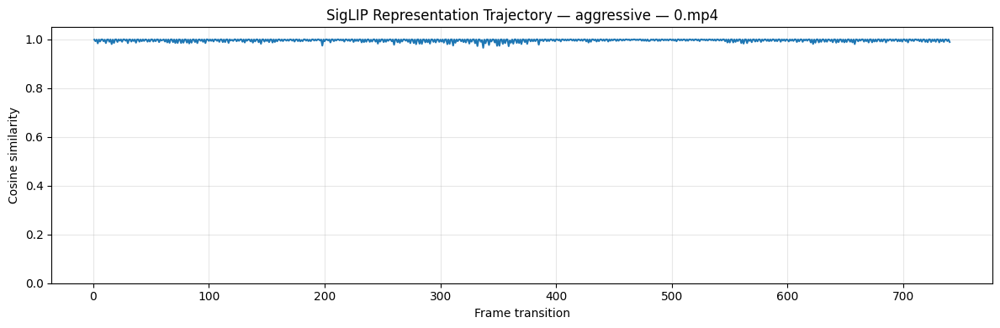

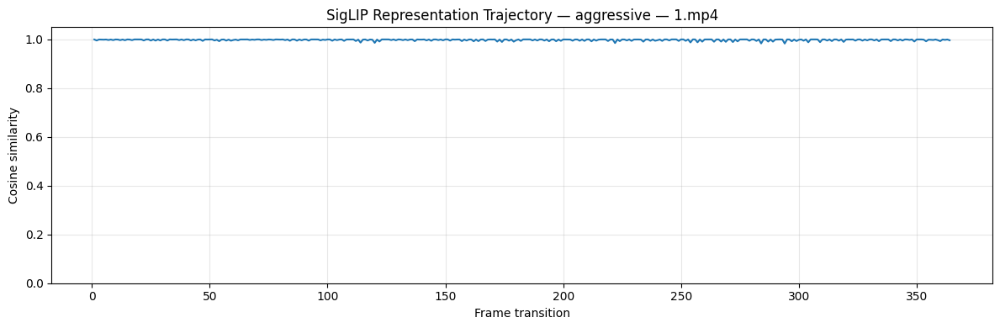

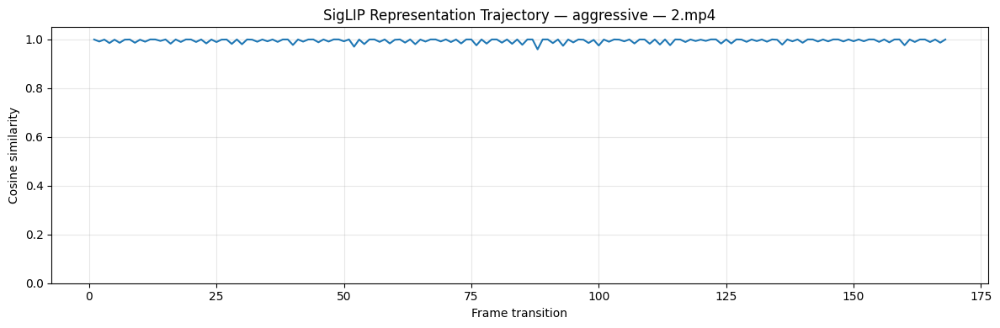

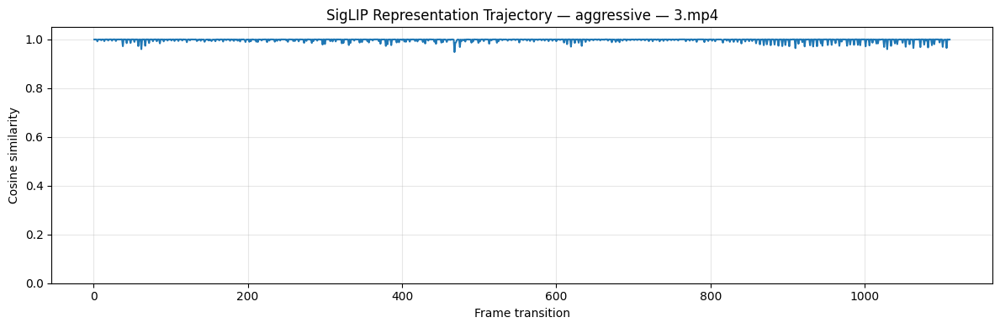

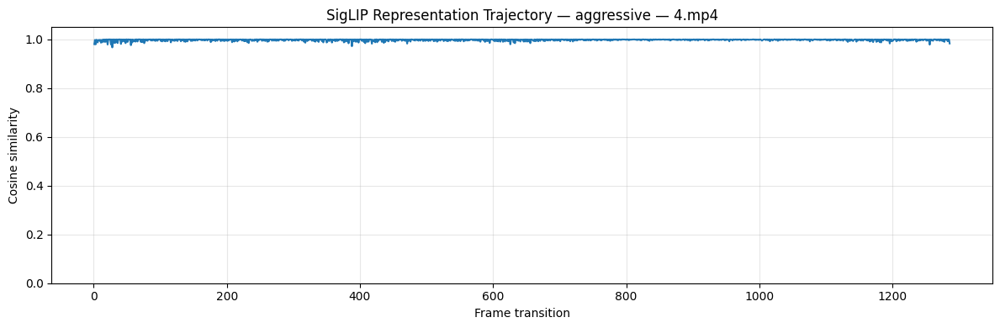

...

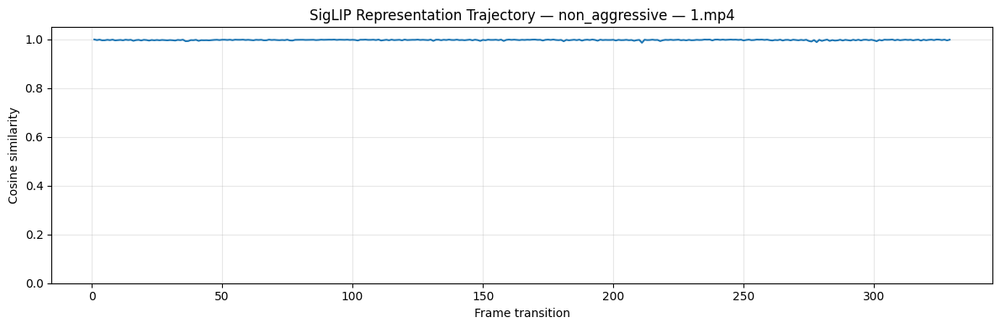

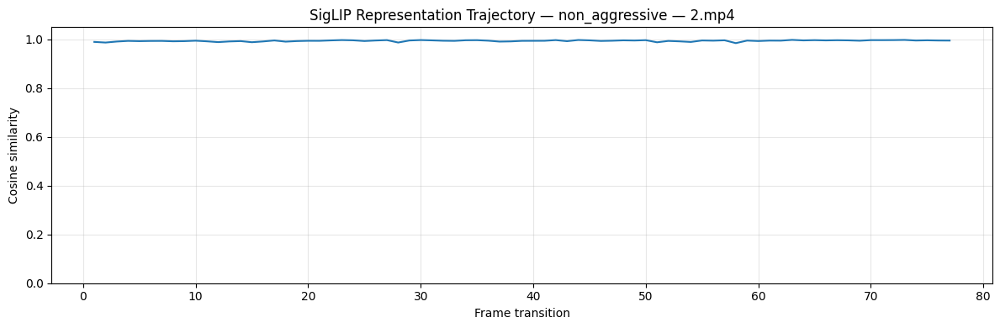

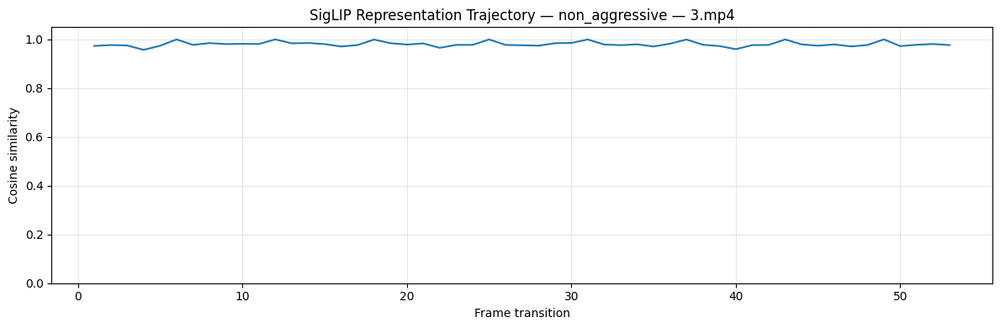

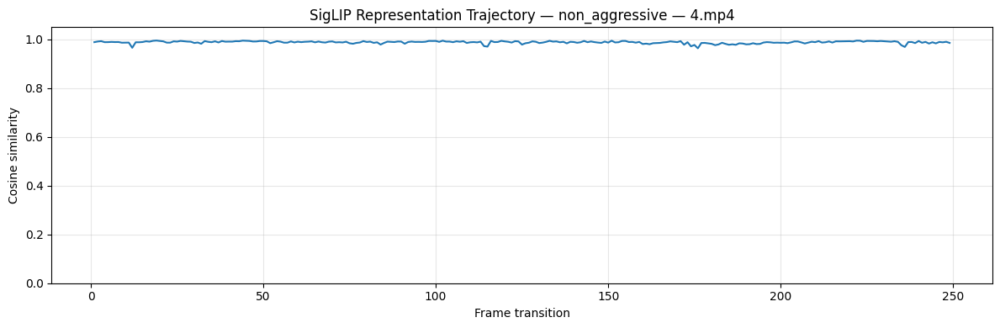

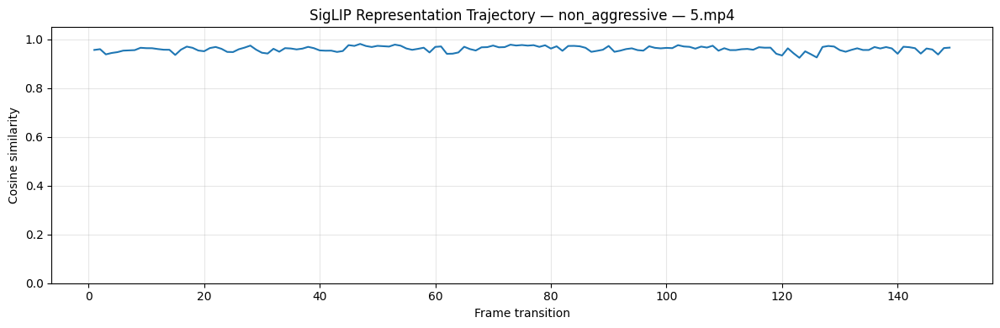

In [117]:
for key, data in video_embeddings.items():

    plot_representation_trajectory(data)

In [118]:
class_summary = (
    representation_df
    .groupby("class")
    .agg(
        mean_similarity=("mean_similarity", "mean"),
        mean_embedding_change=("mean_embedding_change", "mean"),
        std_embedding_change=("mean_embedding_change", "std")
    )
    .reset_index()
)

class_summary

,class,mean_similarity,mean_embedding_change,std_embedding_change
0,aggressive,0.996394,0.003606,0.001587
1,non_aggressive,0.981970,0.018030,0.014134


Observation:
1.We expected that aggresive videos will have very high variance in embedding change but we are seeing opposite of that instead non-aggressive videos have higher variance in embedding change.
2.But it is evident that there are many disturbances in trajectory of aggressive videos rather than non-aggresive videos.

In [119]:
from scipy.signal import find_peaks

# ============================================================
# DETECT REPRESENTATION-CHANGE PEAKS
# ============================================================

peak_results = []

for key, data in video_embeddings.items():

    embeddings = data["embeddings"]

    similarities = consecutive_cosine_similarity(
        embeddings
    )

    # Convert similarity to representation change
    changes = 1 - similarities

    # Detect prominent peaks
    peaks, properties = find_peaks(
        changes,
        prominence=0.001,
        distance=5
    )

    peak_results.append({
        "video": data["video"],
        "class": data["class"],
        "num_frames": len(embeddings),
        "num_peaks": len(peaks),
        "mean_peak_change": (
            changes[peaks].mean()
            if len(peaks) > 0 else 0
        ),
        "max_peak_change": (
            changes[peaks].max()
            if len(peaks) > 0 else 0
        ),
        "peak_positions": peaks
    })

peak_df = pd.DataFrame(peak_results)

peak_df

,video,class,num_frames,num_peaks,mean_peak_change,max_peak_change,peak_positions
0,0.mp4,aggressive,741,119,0.011801,0.034480,"[3, 10, 15, 20, 29, 36, 41, 46, 51, 56, 65, 70..."
1,1.mp4,aggressive,365,61,0.007224,0.016929,"[1, 8, 13, 21, 26, 31, 36, 41, 46, 53, 58, 66,..."
2,2.mp4,aggressive,169,28,0.017777,0.040904,"[3, 8, 15, 22, 29, 34, 39, 44, 51, 58, 63, 70,..."
3,3.mp4,aggressive,1111,161,0.013883,0.052132,"[4, 13, 18, 23, 28, 37, 42, 47, 52, 61, 66, 71..."
4,4.mp4,aggressive,1287,207,0.007395,0.032992,"[2, 10, 15, 20, 27, 35, 40, 47, 55, 62, 70, 75..."
5,0.mp4,non_aggressive,96,12,0.040101,0.058951,"[5, 11, 20, 26, 35, 45, 52, 60, 66, 75, 82, 88]"
6,1.mp4,non_aggressive,330,45,0.004868,0.013928,"[3, 8, 15, 21, 28, 35, 40, 48, 53, 65, 71, 76,..."
7,2.mp4,non_aggressive,78,10,0.009880,0.015380,"[1, 7, 14, 27, 36, 42, 50, 57, 63, 68]"
8,3.mp4,non_aggressive,54,8,0.031256,0.042830,"[3, 8, 15, 21, 27, 34, 39, 46]"
9,4.mp4,non_aggressive,250,33,0.017395,0.036592,"[3, 11, 16, 22, 31, 36, 46, 51, 58, 67, 75, 83..."


In [120]:
peak_summary = (
    peak_df
    .groupby("class")
    .agg(
        mean_num_peaks=("num_peaks", "mean"),
        mean_peak_change=("mean_peak_change", "mean"),
        max_peak_change=("max_peak_change", "mean")
    )
    .reset_index()
)

peak_summary

,class,mean_num_peaks,mean_peak_change,max_peak_change
0,aggressive,115.200000,0.011616,0.035488
1,non_aggressive,21.666667,0.025559,0.040531


####  Now we can see clearly see that number of peaks are very high in aggressive videos

## Video Level Representation

In [121]:
# ============================================================
# VIDEO-LEVEL REPRESENTATION USING MEAN POOLING
# ============================================================

video_vectors = {}

for key, data in video_embeddings.items():

    # Average all frame embeddings
    video_vector = data["embeddings"].mean(axis=0)

    # L2 normalize
    video_vector = video_vector / (
        np.linalg.norm(video_vector) + 1e-8
    )

    video_vectors[key] = {
        "video": data["video"],
        "class": data["class"],
        "vector": video_vector
    }

In [122]:
from sklearn.metrics.pairwise import cosine_similarity

keys = list(video_vectors.keys())

X = np.stack([
    video_vectors[key]["vector"]
    for key in keys
])

similarity_matrix = cosine_similarity(X)

labels = [
    f"{video_vectors[key]['video']}\n{video_vectors[key]['class']}"
    for key in keys
]

similarity_matrix.shape

(11, 11)

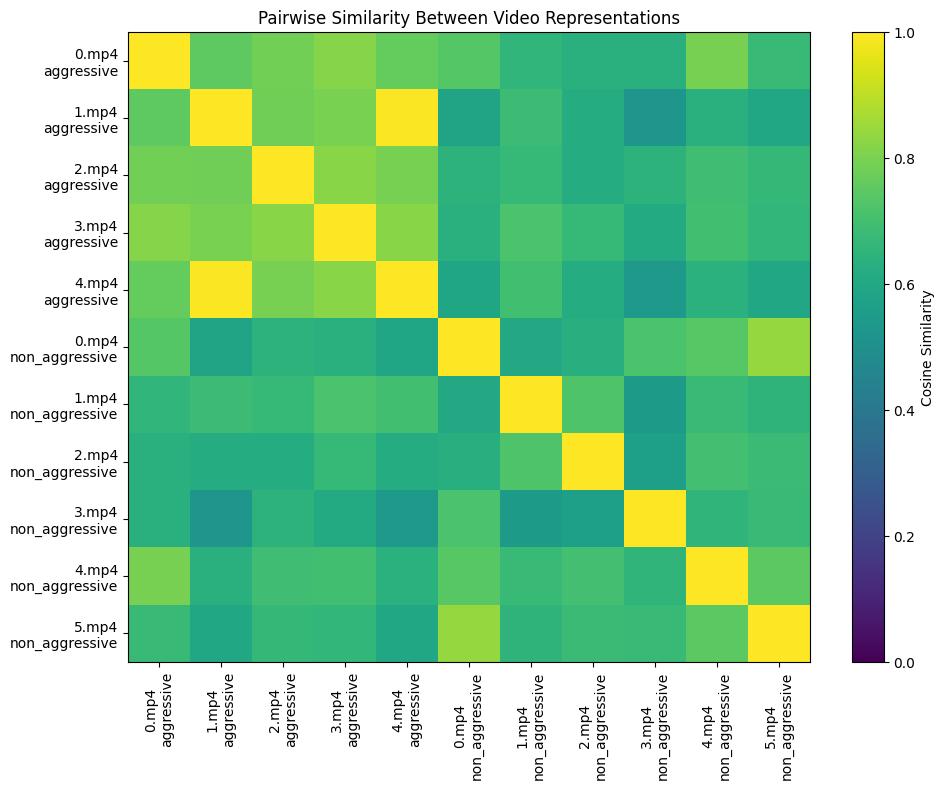

In [123]:
plt.figure(figsize=(10, 8))

plt.imshow(
    similarity_matrix,
    vmin=0,
    vmax=1,
    aspect="auto"
)

plt.colorbar(label="Cosine Similarity")

labels = [
    f"{video_vectors[key]['video']}\n"
    f"{video_vectors[key]['class']}"
    for key in keys
]

plt.xticks(
    range(len(labels)),
    labels,
    rotation=90
)

plt.yticks(
    range(len(labels)),
    labels
)

plt.title("Pairwise Similarity Between Video Representations")

plt.tight_layout()
plt.show()

In [ ]:
encoders = {
    "CLIP": "openai/clip-vit-base-patch32",
    "DINOv2": "facebook/dinov2-base"
}

In [ ]:
# ============================================================
# CACHE ALL VIDEO FRAMES
# ============================================================

video_frames = {}

for video_path, label in tqdm(
    all_videos,
    desc="Loading video frames"
):

    frames, indices = load_all_frames(video_path)

    key = video_path.name + "_" + label

    video_frames[key] = {
        "video": video_path.name,
        "class": label,
        "frame_indices": indices,
        "frames": frames
    }

print("Videos cached:", len(video_frames))

### CLIP

In [ ]:
from transformers import CLIPProcessor, CLIPModel

CLIP_MODEL = "openai/clip-vit-base-patch32"

clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL)
clip_model = CLIPModel.from_pretrained(CLIP_MODEL).to(DEVICE)

clip_model.eval()

In [ ]:
# ============================================================
# CLIP FRAME EMBEDDING EXTRACTION
# ============================================================

@torch.no_grad()
def extract_clip_embeddings(frames, batch_size=8):

    all_embeddings = []

    for start in range(0, len(frames), batch_size):

        batch = frames[start:start + batch_size]

        inputs = clip_processor(
            images=batch,
            return_tensors="pt"
        )

        pixel_values = inputs["pixel_values"].to(DEVICE)

        # CLIP vision encoder
        outputs = clip_model.vision_model(
            pixel_values=pixel_values
        )

        # Pooled visual representation
        image_features = outputs.pooler_output

        # Project into CLIP embedding space
        image_features = clip_model.visual_projection(
            image_features
        )

        # L2 normalization
        image_features = torch.nn.functional.normalize(
            image_features,
            p=2,
            dim=-1
        )

        all_embeddings.append(
            image_features.cpu().numpy()
        )

    return np.concatenate(all_embeddings, axis=0)

In [ ]:
clip_embeddings = {}

for key, data in tqdm(
    video_frames.items(),
    desc="Extracting CLIP embeddings"
):

    embeddings = extract_clip_embeddings(
        data["frames"],
        batch_size=8
    )

    clip_embeddings[key] = {
        "video": data["video"],
        "class": data["class"],
        "frame_indices": data["frame_indices"],
        "embeddings": embeddings
    }

print("Videos processed:", len(clip_embeddings))

### Loading DINOV2

In [ ]:
from transformers import AutoImageProcessor, AutoModel

DINO_MODEL = "facebook/dinov2-base"

dino_processor = AutoImageProcessor.from_pretrained(
    DINO_MODEL
)

dino_model = AutoModel.from_pretrained(
    DINO_MODEL
).to(DEVICE)

dino_model.eval()

In [ ]:
@torch.no_grad()
def extract_dino_embeddings(frames, batch_size=8):

    all_embeddings = []

    for start in range(0, len(frames), batch_size):

        batch = frames[start:start + batch_size]

        inputs = dino_processor(
            images=batch,
            return_tensors="pt"
        )

        inputs = {
            k: v.to(DEVICE)
            for k, v in inputs.items()
        }

        outputs = dino_model(**inputs)

        # CLS token representation
        image_features = outputs.last_hidden_state[:, 0, :]

        image_features = torch.nn.functional.normalize(
            image_features,
            p=2,
            dim=-1
        )

        all_embeddings.append(
            image_features.cpu().numpy()
        )

    return np.concatenate(all_embeddings, axis=0)

In [ ]:
dino_embeddings = {}

for key, data in tqdm(
    video_frames.items(),
    desc="Extracting DINOv2 embeddings"
):

    embeddings = extract_dino_embeddings(
        data["frames"],
        batch_size=8
    )

    dino_embeddings[key] = {
        "video": data["video"],
        "class": data["class"],
        "frame_indices": data["frame_indices"],
        "embeddings": embeddings
    }

print("Videos processed:", len(dino_embeddings))

In [ ]:
def consecutive_cosine_similarity(embeddings):

    return np.sum(
        embeddings[:-1] * embeddings[1:],
        axis=1
    )

In [ ]:
def analyze_frame_similarity(embedding_dict, encoder_name):

    results = []

    for key, data in embedding_dict.items():

        similarities = consecutive_cosine_similarity(
            data["embeddings"]
        )

        results.append({
            "encoder": encoder_name,
            "video": data["video"],
            "class": data["class"],
            "mean_similarity": similarities.mean(),
            "std_similarity": similarities.std(),
            "mean_embedding_change": (
                1 - similarities.mean()
            ),
            "min_similarity": similarities.min()
        })

    return pd.DataFrame(results)

In [ ]:
clip_frame_df = analyze_frame_similarity(
    clip_embeddings,
    "CLIP"
)

dino_frame_df = analyze_frame_similarity(
    dino_embeddings,
    "DINOv2"
)

In [ ]:
siglip_frame_df = representation_df.copy()

siglip_frame_df["encoder"] = "SigLIP"

frame_similarity_all = pd.concat(
    [
        siglip_frame_df,
        clip_frame_df,
        dino_frame_df
    ],
    ignore_index=True
)

frame_similarity_all

In [ ]:
frame_similarity_summary = (
    frame_similarity_all
    .groupby(["encoder", "class"])
    .agg(
        mean_similarity=("mean_similarity", "mean"),
        mean_embedding_change=("mean_embedding_change", "mean"),
        std_embedding_change=("mean_embedding_change", "std")
    )
    .reset_index()
)

frame_similarity_summary

In [ ]:
def create_video_vectors(embedding_dict):

    video_vectors = {}

    for key, data in embedding_dict.items():

        vector = data["embeddings"].mean(axis=0)

        vector = vector / (
            np.linalg.norm(vector) + 1e-8
        )

        video_vectors[key] = {
            "video": data["video"],
            "class": data["class"],
            "vector": vector
        }

    return video_vectors

In [ ]:
siglip_video_vectors = create_video_vectors(
    video_embeddings
)

clip_video_vectors = create_video_vectors(
    clip_embeddings
)

dino_video_vectors = create_video_vectors(
    dino_embeddings
)

In [ ]:
def analyze_video_similarity(video_vectors, encoder_name):

    keys = list(video_vectors.keys())

    X = np.stack([
        video_vectors[key]["vector"]
        for key in keys
    ])

    similarity_matrix = cosine_similarity(X)

    within_aggressive = []
    within_non_aggressive = []
    between_classes = []

    for i in range(len(keys)):

        for j in range(i + 1, len(keys)):

            sim = similarity_matrix[i, j]

            class_i = video_vectors[keys[i]]["class"]
            class_j = video_vectors[keys[j]]["class"]

            if (
                class_i == "aggressive"
                and class_j == "aggressive"
            ):
                within_aggressive.append(sim)

            elif (
                class_i == "non_aggressive"
                and class_j == "non_aggressive"
            ):
                within_non_aggressive.append(sim)

            else:
                between_classes.append(sim)

    return {
        "encoder": encoder_name,
        "aggressive_aggressive":
            np.mean(within_aggressive),
        "non_aggressive_non_aggressive":
            np.mean(within_non_aggressive),
        "aggressive_non_aggressive":
            np.mean(between_classes),
        "aggressive_separation":
            np.mean(within_aggressive)
            - np.mean(between_classes),
        "non_aggressive_separation":
            np.mean(within_non_aggressive)
            - np.mean(between_classes)
    }

In [ ]:
video_similarity_results = pd.DataFrame([
    
    analyze_video_similarity(
        siglip_video_vectors,
        "SigLIP"
    ),

    analyze_video_similarity(
        clip_video_vectors,
        "CLIP"
    ),

    analyze_video_similarity(
        dino_video_vectors,
        "DINOv2"
    )
])

video_similarity_results

* All three encoders show higher within-class similarity than between-class similarity
* CLIP gives the strongest aggressive-class separation

### Single frame vs Temporal Model

### time -temporal windows

*Design
- Temporal window: 1 second
- Stride: 0.5 seconds
- Frames sampled per window: 16
- Sampling is based on time, not raw frame count
- Label inherited from the source video
- Split remains at source-video level
- Visual representation: SigLIP
- Temporal model: GRU
- Baseline: single middle frame + MLP

In [9]:
WINDOW_SEC = 1.0
STRIDE_SEC = 0.5
NUM_SAMPLED_FRAMES = 16

print("Window duration:", WINDOW_SEC, "sec")
print("Window stride:", STRIDE_SEC, "sec")
print("Frames per window:", NUM_SAMPLED_FRAMES)

Window duration: 1.0 sec
Window stride: 0.5 sec
Frames per window: 16


In [10]:
import cv2
import numpy as np


def load_video_frames_with_time(video_path):
    
    cap = cv2.VideoCapture(str(video_path))

    fps = cap.get(cv2.CAP_PROP_FPS)
    
    frames = []
    frame_indices = []
    timestamps = []

    frame_idx = 0

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frames.append(frame)
        frame_indices.append(frame_idx)

        timestamps.append(frame_idx / fps)

        frame_idx += 1

    cap.release()

    return (
        frames,
        np.array(frame_indices),
        np.array(timestamps),
        fps
    )

In [11]:
def create_time_windows(
    frames,
    timestamps,
    window_sec=1.0,
    stride_sec=0.5,
    num_samples=16
):
    
    windows = []

    video_duration = timestamps[-1]

    start_time = 0.0

    while start_time + window_sec <= video_duration:

        end_time = start_time + window_sec

        # Frames belonging to this temporal window
        mask = (
            (timestamps >= start_time) &
            (timestamps < end_time)
        )

        candidate_indices = np.where(mask)[0]

        if len(candidate_indices) >= 2:

            # Uniformly sample fixed number of frames
            sampled_positions = np.linspace(
                candidate_indices[0],
                candidate_indices[-1],
                num_samples
            ).astype(int)

            sampled_positions = np.clip(
                sampled_positions,
                candidate_indices[0],
                candidate_indices[-1]
            )

            sampled_positions = np.unique(
                sampled_positions
            )

            # If duplicate indices occur, skip this window
            if len(sampled_positions) == num_samples:

                sampled_frames = [
                    frames[i]
                    for i in sampled_positions
                ]

                windows.append({
                    "start_time": start_time,
                    "end_time": end_time,
                    "frame_indices": sampled_positions,
                    "frames": sampled_frames
                })

        start_time += stride_sec

    return windows

In [12]:
video_path, label = all_videos[0]

frames, frame_indices, timestamps, fps = (
    load_video_frames_with_time(video_path)
)

windows = create_time_windows(
    frames,
    timestamps,
    window_sec=WINDOW_SEC,
    stride_sec=STRIDE_SEC,
    num_samples=NUM_SAMPLED_FRAMES
)

print("Video:", video_path.name)
print("Class:", label)
print("FPS:", fps)
print("Total frames:", len(frames))
print("Duration:", timestamps[-1])
print("Number of windows:", len(windows))

NameError: name 'all_videos' is not defined

In [ ]:
first_window = windows[0]

print(
    "Window:",
    first_window["start_time"],
    "→",
    first_window["end_time"]
)

print(
    "Frame indices:",
    first_window["frame_indices"]
)

In [25]:
temporal_windows = []

for video_path, label in all_videos:

    print(f"Processing {video_path.name} ({label})")

    frames, frame_indices, timestamps, fps = (
        load_video_frames_with_time(video_path)
    )

    windows = create_time_windows(
        frames,
        timestamps,
        window_sec=WINDOW_SEC,
        stride_sec=STRIDE_SEC,
        num_samples=NUM_SAMPLED_FRAMES
    )

    numeric_label = (
        1 if label == "aggressive"
        else 0
    )

    for window_id, window in enumerate(windows):

        temporal_windows.append({

            "source_video": video_path.name,

            "source_key": (
                f"{video_path.name}_{label}"
            ),

            "class": label,

            "label": numeric_label,

            "window_id": window_id,

            "start_time": window["start_time"],

            "end_time": window["end_time"],

            "frame_indices": (
                window["frame_indices"]
            ),

            "frames": window["frames"]

        })

Processing 0.mp4 (aggressive)
Processing 1.mp4 (aggressive)
Processing 2.mp4 (aggressive)
Processing 3.mp4 (aggressive)
Processing 4.mp4 (aggressive)
Processing 0.mp4 (non_aggressive)
Processing 1.mp4 (non_aggressive)
Processing 2.mp4 (non_aggressive)
Processing 3.mp4 (non_aggressive)
Processing 4.mp4 (non_aggressive)
Processing 5.mp4 (non_aggressive)


In [ ]:
window_df = pd.DataFrame([
    {
        "source_video": x["source_video"],
        "source_key": x["source_key"],
        "class": x["class"],
        "label": x["label"],
        "window_id": x["window_id"],
        "start_time": x["start_time"],
        "end_time": x["end_time"]
    }
    for x in temporal_windows
])

print("Total temporal windows:",
      len(window_df))

print("\nWindows by class:")
print(
    window_df["class"].value_counts()
)

print("\nWindows by source video:")
print(
    window_df.groupby(
        ["class", "source_video"]
    ).size()
)

In [ ]:
video_split_new = {

    "train": {
        "aggressive": [
            "0.mp4",
            "1.mp4",
            "3.mp4"
        ],
        "non_aggressive": [
            "0.mp4",
            "2.mp4",
            "3.mp4",
            "5.mp4"
        ]
    },

    "val": {
        "aggressive": [
            "2.mp4"
        ],
        "non_aggressive": [
            "4.mp4"
        ]
    },

    "test": {
        "aggressive": [
            "4.mp4"
        ],
        "non_aggressive": [
            "1.mp4"
        ]
    }
}

In [ ]:
def assign_split(row):

    video = row["source_video"]
    class_name = row["class"]

    for split, classes in video_split_new.items():

        if video in classes[class_name]:
            return split

    return None


window_df["split"] = window_df.apply(
    assign_split,
    axis=1
)

In [ ]:
print(
    window_df.groupby(
        ["split", "class"]
    ).size()
)

In [ ]:
for split in ["train", "val", "test"]:

    print(
        f"\n{split.upper()} VIDEOS"
    )

    print(
        window_df[
            window_df["split"] == split
        ][
            ["source_key", "class"]
        ].drop_duplicates()
    )

In [ ]:
print(
    window_df.groupby(
        ["split", "class"]
    ).size()
)

### extract sglip embeddings

In [ ]:
import torch
import numpy as np
from tqdm.auto import tqdm
from transformers import AutoProcessor, SiglipModel

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "google/siglip-base-patch16-224"

processor = AutoProcessor.from_pretrained(
    MODEL_NAME
)

siglip_model = SiglipModel.from_pretrained(
    MODEL_NAME
).to(DEVICE)

siglip_model.eval()

print("Device:", DEVICE)

In [ ]:
@torch.no_grad()
def extract_siglip_embeddings(
    frames,
    batch_size=8
):

    all_embeddings = []

    for start in range(
        0,
        len(frames),
        batch_size
    ):

        batch = frames[
            start:start + batch_size
        ]

        inputs = processor(
            images=batch,
            return_tensors="pt"
        )

        pixel_values = (
            inputs["pixel_values"]
            .to(DEVICE)
        )

        outputs = siglip_model.vision_model(
            pixel_values=pixel_values
        )

        image_features = (
            outputs.pooler_output
        )

        image_features = torch.nn.functional.normalize(
            image_features,
            p=2,
            dim=-1
        )

        all_embeddings.append(
            image_features.cpu().numpy()
        )

    return np.concatenate(
        all_embeddings,
        axis=0
    )

In [ ]:
window_embeddings = []

for i, sample in enumerate(
    tqdm(
        temporal_windows,
        desc="Extracting temporal embeddings"
    )
):

    embeddings = extract_siglip_embeddings(
        sample["frames"],
        batch_size=8
    )

    window_embeddings.append(
        embeddings
    )

In [ ]:
print(
    "Number of windows:",
    len(window_embeddings)
)

print(
    "First window shape:",
    window_embeddings[0].shape
)

In [ ]:
window_df["embeddings"] = window_embeddings

In [ ]:
window_df.head()

In [ ]:
def build_split_arrays(
    df,
    split
):

    subset = df[
        df["split"] == split
    ]

    X = np.stack(
        subset["embeddings"].values
    )

    y = subset["label"].values

    return X, y

In [ ]:
X_train_new, y_train_new = build_split_arrays(
    window_df,
    "train"
)

X_val_new, y_val_new = build_split_arrays(
    window_df,
    "val"
)

X_test_new, y_test_new = build_split_arrays(
    window_df,
    "test"
)

In [ ]:
print(
    "Train:",
    X_train_new.shape,
    y_train_new.shape
)

print(
    "Val:",
    X_val_new.shape,
    y_val_new.shape
)

print(
    "Test:",
    X_test_new.shape,
    y_test_new.shape
)

In [ ]:
NEW_DATA_DIR = "/kaggle/working/temporal_1sec_dataset"

import os
os.makedirs(
    NEW_DATA_DIR,
    exist_ok=True
)

np.save(
    f"{NEW_DATA_DIR}/X_train.npy",
    X_train_new
)

np.save(
    f"{NEW_DATA_DIR}/y_train.npy",
    y_train_new
)

np.save(
    f"{NEW_DATA_DIR}/X_val.npy",
    X_val_new
)

np.save(
    f"{NEW_DATA_DIR}/y_val.npy",
    y_val_new
)

np.save(
    f"{NEW_DATA_DIR}/X_test.npy",
    X_test_new
)

np.save(
    f"{NEW_DATA_DIR}/y_test.npy",
    y_test_new
)

# Save metadata without the large embedding column
metadata_to_save = window_df.drop(
    columns=["embeddings"]
)

metadata_to_save.to_csv(
    f"{NEW_DATA_DIR}/window_metadata.csv",
    index=False
)

print(
    f"Saved new dataset to {NEW_DATA_DIR}"
)

In [2]:
import os
import numpy as np
import pandas as pd

NEW_DATA_DIR = "/kaggle/working/temporal_1sec_dataset"

# Load embeddings
X_train_new = np.load(f"{NEW_DATA_DIR}/X_train.npy")
X_val_new   = np.load(f"{NEW_DATA_DIR}/X_val.npy")
X_test_new  = np.load(f"{NEW_DATA_DIR}/X_test.npy")

# Load labels
y_train_new = np.load(f"{NEW_DATA_DIR}/y_train.npy")
y_val_new   = np.load(f"{NEW_DATA_DIR}/y_val.npy")
y_test_new  = np.load(f"{NEW_DATA_DIR}/y_test.npy")

# Load metadata
window_df = pd.read_csv(
    f"{NEW_DATA_DIR}/window_metadata.csv"
)

print("Loaded successfully")
print()
print("X_train:", X_train_new.shape)
print("y_train:", y_train_new.shape)
print("X_val:  ", X_val_new.shape)
print("y_val:  ", y_val_new.shape)
print("X_test: ", X_test_new.shape)
print("y_test: ", y_test_new.shape)
print("Metadata:", window_df.shape)

Loaded successfully

X_train: (89, 16, 768)
y_train: (89,)
X_val:   (19, 16, 768)
y_val:   (19,)
X_test:  (61, 16, 768)
y_test:  (61,)
Metadata: (169, 8)


In [3]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)


class TemporalDataset(Dataset):

    def __init__(self, X, y):
        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )
        self.y = torch.tensor(
            y,
            dtype=torch.long
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_dataset = TemporalDataset(
    X_train_new,
    y_train_new
)

val_dataset = TemporalDataset(
    X_val_new,
    y_val_new
)

test_dataset = TemporalDataset(
    X_test_new,
    y_test_new
)

Device: cuda


In [4]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

## GRU

In [5]:
class TemporalGRU(nn.Module):

    def __init__(
        self,
        input_dim=768,
        hidden_dim=128
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)
        )

    def forward(self, x):

        # x: [batch, 16, 768]

        output, hidden = self.gru(x)

        # Representation after the final observation
        temporal_representation = output[:, -1, :]

        logits = self.classifier(
            temporal_representation
        )

        return logits

In [ ]:
model_new = TemporalGRU(
    input_dim=X_train_new.shape[-1],
    hidden_dim=128
).to(DEVICE)

print(model_new)

In [ ]:
unique, counts = np.unique(
    y_train_new,
    return_counts=True
)

print(
    dict(zip(unique, counts))
)

In [ ]:
class_counts = np.bincount(
    y_train_new
)

class_weights = (
    len(y_train_new) /
    (2 * class_counts)
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(DEVICE)

print("Class weights:", class_weights)

In [ ]:
criterion_new = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_new = torch.optim.AdamW(
    model_new.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [ ]:
def train_one_epoch_new(
    model,
    loader,
    criterion,
    optimizer
):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for X, y in loader:

        X = X.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()

        logits = model(X)

        loss = criterion(
            logits,
            y
        )

        loss.backward()

        optimizer.step()

        total_loss += (
            loss.item() * len(y)
        )

        predictions = logits.argmax(
            dim=1
        )

        correct += (
            predictions == y
        ).sum().item()

        total += len(y)

    return (
        total_loss / total,
        correct / total
    )

In [ ]:
def evaluate_new(
    model,
    loader,
    criterion
):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []
    all_probabilities = []

    with torch.no_grad():

        for X, y in loader:

            X = X.to(DEVICE)
            y = y.to(DEVICE)

            logits = model(X)

            loss = criterion(
                logits,
                y
            )

            probabilities = torch.softmax(
                logits,
                dim=1
            )

            predictions = logits.argmax(
                dim=1
            )

            total_loss += (
                loss.item() * len(y)
            )

            correct += (
                predictions == y
            ).sum().item()

            total += len(y)

            all_labels.extend(
                y.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities[:, 1]
                .cpu()
                .numpy()
            )

    return (
        total_loss / total,
        correct / total,
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_probabilities)
    )

In [ ]:
NUM_EPOCHS = 30

history_new = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

best_val_loss = float("inf")
best_state = None

for epoch in range(NUM_EPOCHS):

    train_loss, train_acc = (
        train_one_epoch_new(
            model_new,
            train_loader,
            criterion_new,
            optimizer_new
        )
    )

    (
        val_loss,
        val_acc,
        _,
        _,
        _
    ) = evaluate_new(
        model_new,
        val_loader,
        criterion_new
    )

    history_new["train_loss"].append(
        train_loss
    )

    history_new["train_acc"].append(
        train_acc
    )

    history_new["val_loss"].append(
        val_loss
    )

    history_new["val_acc"].append(
        val_acc
    )

    # Save best validation model
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_state = {
            k: v.cpu().clone()
            for k, v in model_new.state_dict().items()
        }

    print(
        f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

In [ ]:
model_new.load_state_dict(
    best_state
)

model_new = model_new.to(DEVICE)

In [ ]:
(
    test_loss_new,
    test_acc_new,
    y_true_new,
    y_pred_new,
    y_prob_new
) = evaluate_new(
    model_new,
    test_loader,
    criterion_new
)

print(
    "Test Accuracy:",
    test_acc_new
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print(
    "Accuracy :",
    accuracy_score(y_true_new, y_pred_new)
)

print(
    "Precision:",
    precision_score(
        y_true_new,
        y_pred_new,
        zero_division=0
    )
)

print(
    "Recall   :",
    recall_score(
        y_true_new,
        y_pred_new,
        zero_division=0
    )
)

print(
    "F1       :",
    f1_score(
        y_true_new,
        y_pred_new,
        zero_division=0
    )
)

print(
    "ROC-AUC  :",
    roc_auc_score(
        y_true_new,
        y_prob_new
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_true_new,
        y_pred_new
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_true_new,
        y_pred_new,
        target_names=[
            "non_aggressive",
            "aggressive"
        ],
        zero_division=0
    )
)

 1. Classification report clearly says that there is source-video bias
 2. Although test accuracy is giving us 1 ,but validation accuracy was decreasing and loss was increasing

### Single-Frame MLP

In [ ]:
# Mean-pool the 16 frame embeddings within each temporal window
X_train_mlp = X_train_new.mean(axis=1)
X_val_mlp   = X_val_new.mean(axis=1)
X_test_mlp  = X_test_new.mean(axis=1)

print("Train:", X_train_mlp.shape)
print("Val:", X_val_mlp.shape)
print("Test:", X_test_mlp.shape)

In [ ]:
class MLPDataset(torch.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_mlp_dataset = MLPDataset(X_train_mlp, y_train_new)
val_mlp_dataset   = MLPDataset(X_val_mlp, y_val_new)
test_mlp_dataset  = MLPDataset(X_test_mlp, y_test_new)

train_mlp_loader = DataLoader(train_mlp_dataset, batch_size=16, shuffle=True)
val_mlp_loader   = DataLoader(val_mlp_dataset, batch_size=16, shuffle=False)
test_mlp_loader  = DataLoader(test_mlp_dataset, batch_size=16, shuffle=False)

In [ ]:
class FrameMLP(nn.Module):
    def __init__(self, input_dim=768):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
mlp_model = FrameMLP().to(DEVICE)

class_counts = np.bincount(y_train_new)
class_weights = len(y_train_new) / (2 * class_counts)

criterion_mlp = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
)

optimizer_mlp = torch.optim.AdamW(
    mlp_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [ ]:
num_epochs = 50

best_val_loss = float("inf")
best_state = None

for epoch in range(num_epochs):

    # ---- Training ----
    mlp_model.train()
    train_loss = 0

    for X_batch, y_batch in train_mlp_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer_mlp.zero_grad()

        logits = mlp_model(X_batch)
        loss = criterion_mlp(logits, y_batch)

        loss.backward()
        optimizer_mlp.step()

        train_loss += loss.item() * len(y_batch)

    train_loss /= len(train_mlp_dataset)

    # ---- Validation ----
    mlp_model.eval()
    val_loss = 0

    with torch.no_grad():
        for X_batch, y_batch in val_mlp_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = mlp_model(X_batch)
            loss = criterion_mlp(logits, y_batch)

            val_loss += loss.item() * len(y_batch)

    val_loss /= len(val_mlp_dataset)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            k: v.cpu().clone()
            for k, v in mlp_model.state_dict().items()
        }

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch {epoch+1:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

# Restore best validation model
mlp_model.load_state_dict(best_state)
mlp_model.to(DEVICE)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

def evaluate_mlp(model, loader):

    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():
        for X_batch, y_batch in loader:

            X_batch = X_batch.to(DEVICE)

            logits = model(X_batch)
            probs = torch.softmax(logits, dim=1)

            preds = torch.argmax(probs, dim=1)

            y_true.extend(y_batch.numpy())
            y_pred.extend(preds.cpu().numpy())
            y_prob.extend(probs[:, 1].cpu().numpy())

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    return metrics, np.array(y_true), np.array(y_pred), np.array(y_prob)


mlp_metrics, mlp_y_true, mlp_y_pred, mlp_y_prob = evaluate_mlp(
    mlp_model,
    test_mlp_loader
)

print(mlp_metrics)
print("\nConfusion Matrix:")
print(confusion_matrix(mlp_y_true, mlp_y_pred))

### Observation - If a single frame MLP is getting 98 % accuracy and if GRU is at 100 % that means temporal informance sequence is not mattering much here

### Temporal Evaluation

#### Shuffled temporal order

In [ ]:
results = []

for seed in range(10):

    X_test_shuffled = X_test_new.copy()

    rng = np.random.default_rng(seed)

    for i in range(len(X_test_shuffled)):
        rng.shuffle(X_test_shuffled[i])

    shuffled_dataset = TemporalDataset(
        X_test_shuffled,
        y_test_new
    )

    shuffled_loader = DataLoader(
        shuffled_dataset,
        batch_size=16,
        shuffle=False
    )

    (
        loss,
        acc,
        y_true,
        y_pred,
        y_prob
    ) = evaluate_new(
        model_new,
        shuffled_loader,
        criterion_new
    )

    precision = precision_score(
        y_true, y_pred, zero_division=0
    )

    recall = recall_score(
        y_true, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    auc = roc_auc_score(
        y_true, y_prob
    )

    results.append({
        "seed": seed,
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc
    })

results_df = pd.DataFrame(results)

results_df

#### Shuffling didnt have a effect on performance metrics , which says that temporal information is not helpful in our prediction

#### Changing number of frames

In [ ]:
progressive_results = []

observation_counts = [1, 2, 4, 8, 16]

for n_frames in observation_counts:

    # Keep only the first n observations
    X_test_progressive = X_test_new[:, :n_frames, :]

    test_dataset = TemporalDataset(
        X_test_progressive,
        y_test_new
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=16,
        shuffle=False
    )

    (
        loss,
        acc,
        y_true,
        y_pred,
        y_prob
    ) = evaluate_new(
        model_new,
        test_loader,
        criterion_new
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_true,
        y_prob
    )

    progressive_results.append({
        "observations": n_frames,
        "accuracy": acc,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": auc
    })

progressive_df = pd.DataFrame(progressive_results)

progressive_df

1. After number of frames = 4 ,accuracy saturates
2. at no of observations = 1 , simple MLP has better accuracy than GRU

### VLM Component

In [26]:
test_windows = [
    w for w in temporal_windows
    if w["source_key"] in ["4.mp4_aggressive", "1.mp4_non_aggressive"]
]

print("Total test windows:", len(test_windows))

Total test windows: 61


In [27]:
w = test_windows[0]

print(
    w["source_key"],
    w["start_time"],
    w["end_time"],
    w["label"]
)

print("Number of frames:", len(w["frames"]))

4.mp4_aggressive 0.0 1.0 1
Number of frames: 16


In [28]:
early_frames = w["frames"][:4]
late_frames  = w["frames"][-4:]

In [29]:
test_windows = [
    w for w in temporal_windows
    if w["source_key"] in [
        "4.mp4_aggressive",
        "1.mp4_non_aggressive"
    ]
]

print("Total test windows:", len(test_windows))

from collections import Counter
print(Counter(w["source_key"] for w in test_windows))

Total test windows: 61
Counter({'4.mp4_aggressive': 41, '1.mp4_non_aggressive': 20})


### SmolVLM for experimentation

In [30]:
!pip install -q "transformers>=4.49.0" accelerate

In [31]:
!pip install -q num2words

In [52]:
import gc
import torch

del vlm_model
del vlm_processor

gc.collect()
torch.cuda.empty_cache()

print(
    f"Allocated: {torch.cuda.memory_allocated()/1024**3:.2f} GB"
)

Allocated: 2.62 GB


In [53]:
from transformers import AutoProcessor, AutoModelForImageTextToText

VLM_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"

vlm_processor = AutoProcessor.from_pretrained(VLM_ID)

vlm_model = AutoModelForImageTextToText.from_pretrained(
    VLM_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)

vlm_model.eval()

print("SmolVLM 256M loaded")

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.2k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

SmolVLM 256M loaded


In [60]:
# Reconstruct the SAME 1-second windows used for the temporal experiment

WINDOW_SEC = 1.0
STRIDE_SEC = 0.5
NUM_SAMPLED_FRAMES = 16

test_source_keys = [
    "4.mp4_aggressive",
    "1.mp4_non_aggressive"
]

test_windows = [
    w for w in temporal_windows
    if w["source_key"] in test_source_keys
]

print("Number of test windows:", len(test_windows))
print("Expected: 61")

from collections import Counter
print(Counter(w["source_key"] for w in test_windows))

Number of test windows: 61
Expected: 61
Counter({'4.mp4_aggressive': 41, '1.mp4_non_aggressive': 20})


In [61]:
from PIL import Image

def frames_to_pil(frames):
    return [
        Image.fromarray(frame).convert("RGB")
        for frame in frames
    ]

In [66]:
def select_vlm_frames(frames):
    return [
        frames[0],
        frames[8],
        frames[15]
    ]

In [67]:
VLM_PROMPT = """
These are three video frames in chronological order: EARLY, MIDDLE, LATE.

For each frame:
1. Label it AGGRESSIVE or NON-AGGRESSIVE.
2. Give one short description of what is visible.

Only use visual evidence. Do not invent actions.

Use exactly this format:

EARLY:
Label: ...
Description: ...

MIDDLE:
Label: ...
Description: ...

LATE:
Label: ...
Description: ...

TEMPORAL CHANGE:
Briefly describe what changed from EARLY frames to LATE frames.
"""

In [68]:
from PIL import Image
import torch

def frames_to_pil(frames):
    return [
        Image.fromarray(frame).convert("RGB")
        for frame in frames
    ]


def run_vlm_on_window(
    frames,
    prompt=VLM_PROMPT,
    max_new_tokens=150
):
    
    # Select EARLY / MIDDLE / LATE
    selected_frames = select_vlm_frames(frames)
    
    images = frames_to_pil(selected_frames)

    messages = [
        {
            "role": "user",
            "content": (
                [{"type": "image"} for _ in images]
                + [{"type": "text", "text": prompt}]
            )
        }
    ]

    # Create text prompt
    text = vlm_processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=False
    )

    # Process text + images
    inputs = vlm_processor(
        text=text,
        images=images,
        return_tensors="pt"
    )

    # Move tensors to GPU
    inputs = {
        k: v.to(vlm_model.device)
        if hasattr(v, "to")
        else v
        for k, v in inputs.items()
    }

    # Generate
    with torch.inference_mode():

        output_ids = vlm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    # Remove input tokens
    input_length = inputs["input_ids"].shape[1]

    generated_ids = output_ids[:, input_length:]

    response = vlm_processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    return response

In [69]:
window = test_windows[0]

print("Source:", window["source_video"])
print(
    "Time:",
    f"{window['start_time']:.2f}s - {window['end_time']:.2f}s"
)

response = run_vlm_on_window(
    window["frames"]
)

print("\nVLM OUTPUT:\n")
print(response)

Source: 4.mp4
Time: 0.00s - 1.00s

VLM OUTPUT:

 The people in the image are running away from a car that has crashed into a building. The car crashed into the side of a building, and the people ran away from it.


In [70]:
import matplotlib.pyplot as plt

def visualize_test_window(window):

    frames = window["frames"]

    selected = [
        frames[0],
        frames[8],
        frames[15]
    ]

    labels = [
        "EARLY",
        "MIDDLE",
        "LATE"
    ]

    gt = (
        "AGGRESSIVE"
        if window["label"] == 1
        else "NON-AGGRESSIVE"
    )

    fig, axes = plt.subplots(
        1, 3,
        figsize=(18, 5)
    )

    for ax, frame, name in zip(
        axes,
        selected,
        labels
    ):
        ax.imshow(frame)
        ax.set_title(
            f"{name}\nGround Truth: {gt}",
            fontsize=13,
            fontweight="bold"
        )
        ax.axis("off")

    plt.suptitle(
        f"{window['source_video']} | "
        f"{window['start_time']:.2f}s–{window['end_time']:.2f}s",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

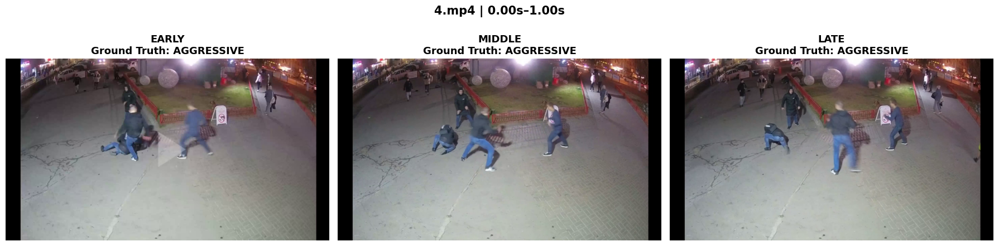

In [71]:
visualize_test_window(test_windows[0])

In [72]:
import numpy as np

# Test windows already contain:
# 41 aggressive windows from 4.mp4
# 20 non-aggressive windows from 1.mp4

aggressive_windows = [
    w for w in test_windows
    if w["label"] == 1
]

non_aggressive_windows = [
    w for w in test_windows
    if w["label"] == 0
]

print("Aggressive windows:", len(aggressive_windows))
print("Non-aggressive windows:", len(non_aggressive_windows))

Aggressive windows: 41
Non-aggressive windows: 20


In [73]:
selected_aggressive = [
    aggressive_windows[0],
    aggressive_windows[len(aggressive_windows)//2],
    aggressive_windows[-1]
]

selected_non_aggressive = [
    non_aggressive_windows[0],
    non_aggressive_windows[len(non_aggressive_windows)//2],
    non_aggressive_windows[-1]
]

selected_windows = (
    selected_aggressive +
    selected_non_aggressive
)

print("Selected windows:", len(selected_windows))

for i, w in enumerate(selected_windows):
    print(
        i,
        w["source_video"],
        f"{w['start_time']:.2f}s - {w['end_time']:.2f}s",
        "AGGRESSIVE" if w["label"] == 1 else "NON-AGGRESSIVE"
    )

Selected windows: 6
0 4.mp4 0.00s - 1.00s AGGRESSIVE
1 4.mp4 10.00s - 11.00s AGGRESSIVE
2 4.mp4 20.00s - 21.00s AGGRESSIVE
3 1.mp4 0.00s - 1.00s NON-AGGRESSIVE
4 1.mp4 5.00s - 6.00s NON-AGGRESSIVE
5 1.mp4 9.50s - 10.50s NON-AGGRESSIVE


In [74]:
vlm_results = []

for i, window in enumerate(selected_windows):

    print(
        f"\n{'='*60}\n"
        f"Sample {i+1}/6\n"
        f"Source: {window['source_video']}\n"
        f"Time: {window['start_time']:.2f}s - "
        f"{window['end_time']:.2f}s\n"
        f"Ground truth: "
        f"{'AGGRESSIVE' if window['label'] == 1 else 'NON-AGGRESSIVE'}"
    )

    response = run_vlm_on_window(
        window["frames"],
        max_new_tokens=150
    )

    print("\nVLM:")
    print(response)

    vlm_results.append({
        "window": window,
        "response": response
    })


Sample 1/6
Source: 4.mp4
Time: 0.00s - 1.00s
Ground truth: AGGRESSIVE

VLM:
 The people in the image are running away from a car that has crashed into a building. The car crashed into the side of a building, and the people ran away from it.

Sample 2/6
Source: 4.mp4
Time: 10.00s - 11.00s
Ground truth: AGGRESSIVE

VLM:
 The people on the right side of the image have moved slightly. The people on the left side of the image have moved a little more.

Sample 3/6
Source: 4.mp4
Time: 20.00s - 21.00s
Ground truth: AGGRESSIVE

VLM:
 From the time the video was taken, people have moved from the middle ground to the foreground.

Sample 4/6
Source: 1.mp4
Time: 0.00s - 1.00s
Ground truth: NON-AGGRESSIVE

VLM:
 The crowd began to move more aggressively.

Sample 5/6
Source: 1.mp4
Time: 5.00s - 6.00s
Ground truth: NON-AGGRESSIVE

VLM:
 The crowd began to move more aggressively.

Sample 6/6
Source: 1.mp4
Time: 9.50s - 10.50s
Ground truth: NON-AGGRESSIVE

VLM:
 The crowd began to get more agitated.


In [75]:
import matplotlib.pyplot as plt

def visualize_multiple_vlm_samples(
    vlm_results,
    n_samples=6
):

    fig, axes = plt.subplots(
        n_samples,
        3,
        figsize=(16, 4.5 * n_samples)
    )

    if n_samples == 1:
        axes = np.expand_dims(axes, axis=0)

    for row, result in enumerate(vlm_results[:n_samples]):

        window = result["window"]

        frames = window["frames"]

        selected_frames = [
            frames[0],
            frames[8],
            frames[15]
        ]

        gt = (
            "AGGRESSIVE"
            if window["label"] == 1
            else "NON-AGGRESSIVE"
        )

        for col, (ax, frame, position) in enumerate(
            zip(
                axes[row],
                selected_frames,
                ["EARLY", "MIDDLE", "LATE"]
            )
        ):

            ax.imshow(frame)
            ax.axis("off")

            ax.set_title(
                f"{position}\nGT: {gt}",
                fontsize=11,
                fontweight="bold"
            )

        # Sample information on left side
        fig.text(
            0.02,
            1 - (row + 0.5) / n_samples,
            f"Sample {row+1}\n"
            f"{window['source_video']}\n"
            f"{window['start_time']:.2f}–"
            f"{window['end_time']:.2f}s",
            ha="left",
            va="center",
            fontsize=10
        )

    plt.suptitle(
        "VLM Temporal Samples: Early → Middle → Late",
        fontsize=18,
        fontweight="bold"
    )

    plt.tight_layout(
        rect=[0.08, 0, 1, 0.97]
    )

    plt.show()

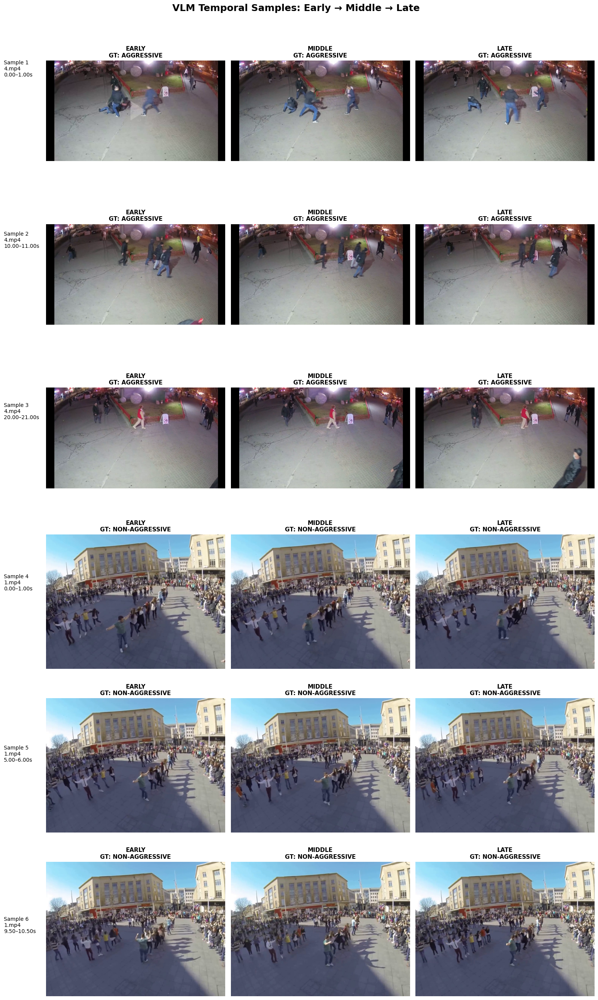

In [76]:
visualize_multiple_vlm_samples(vlm_results)

In [77]:
import re

def parse_vlm_response(response):
    result = {
        "EARLY": {"label": "N/A", "description": ""},
        "MIDDLE": {"label": "N/A", "description": ""},
        "LATE": {"label": "N/A", "description": ""},
        "temporal_change": ""
    }

    # Split response into sections
    pattern = r"(EARLY|MIDDLE|LATE):\s*(.*?)(?=(?:EARLY|MIDDLE|LATE|TEMPORAL CHANGE):|$)"

    matches = re.findall(
        pattern,
        response,
        flags=re.IGNORECASE | re.DOTALL
    )

    for section, content in matches:

        section = section.upper()
        content = content.strip()

        # Extract label
        label_match = re.search(
            r"Label:\s*(AGGRESSIVE|NON-AGGRESSIVE)",
            content,
            flags=re.IGNORECASE
        )

        if label_match:
            result[section]["label"] = (
                label_match.group(1).upper()
            )

        # Extract description
        desc_match = re.search(
            r"Description:\s*(.*)",
            content,
            flags=re.IGNORECASE | re.DOTALL
        )

        if desc_match:
            description = desc_match.group(1).strip()

            # Remove anything that accidentally belongs
            # to another section
            description = re.split(
                r"\n\s*(?:MIDDLE|LATE|TEMPORAL CHANGE):",
                description,
                flags=re.IGNORECASE
            )[0].strip()

            result[section]["description"] = description

    # Temporal change
    temporal_match = re.search(
        r"TEMPORAL CHANGE:\s*(.*)",
        response,
        flags=re.IGNORECASE | re.DOTALL
    )

    if temporal_match:
        result["temporal_change"] = (
            temporal_match.group(1).strip()
        )

    return result

In [79]:
print(vlm_results[0]["response"])

 The people in the image are running away from a car that has crashed into a building. The car crashed into the side of a building, and the people ran away from it.


In [90]:
CLASS_PROMPT = """
Classify this image as exactly one of:
AGGRESSIVE
NON-AGGRESSIVE

Reply with only the class name.
"""

In [91]:
DESCRIPTION_PROMPT = """
Describe this image and events happening.
"""

In [92]:
def run_vlm_prompt(frame, prompt, max_new_tokens=50):

    image = Image.fromarray(frame).convert("RGB")

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": prompt}
            ]
        }
    ]

    text = vlm_processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=False
    )

    inputs = vlm_processor(
        text=text,
        images=[image],
        return_tensors="pt"
    )

    inputs = {
        k: v.to(vlm_model.device)
        if hasattr(v, "to")
        else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        output_ids = vlm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    input_length = inputs["input_ids"].shape[1]

    response = vlm_processor.batch_decode(
        output_ids[:, input_length:],
        skip_special_tokens=True
    )[0].strip()

    return response

In [93]:
frame = test_windows[0]["frames"][0]

pred = run_vlm_prompt(
    frame,
    CLASS_PROMPT,
    max_new_tokens=10
)

description = run_vlm_prompt(
    frame,
    DESCRIPTION_PROMPT,
    max_new_tokens=50
)

print("Prediction:", pred)
print("Description:", description)

Prediction: NON-AGGRESSIVE.
Description: The image shows a nighttime scene featuring a group of people gathered on a paved area. The individuals are interacting with each other, some leaning against a wall, while others are walking or standing. The ground is paved with asphalt, and there are several signs


In [96]:
import matplotlib.pyplot as plt

def run_and_visualize_vlm_samples(selected_windows, max_samples=6):
    results = []

    for sample_idx, window in enumerate(selected_windows[:max_samples]):

        sample_result = {
            "window": window,
            "ground_truth": "AGGRESSIVE" if window["label"] == 1 else "NON-AGGRESSIVE"
        }

        for position, frame_idx in [
            ("EARLY", 0),
            ("MIDDLE", 8),
            ("LATE", 15)
        ]:
            frame = window["frames"][frame_idx]

            prediction = run_vlm_prompt(
                frame,
                CLASS_PROMPT,
                max_new_tokens=10
            ).strip()

            sample_result[position] = {
                "frame": frame,
                "prediction": prediction
            }

        results.append(sample_result)

    # -----------------------------
    # Visualization
    # -----------------------------
    for i, result in enumerate(results):

        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        gt = result["ground_truth"]

        for ax, position in zip(
            axes,
            ["EARLY", "MIDDLE", "LATE"]
        ):
            frame_data = result[position]

            ax.imshow(frame_data["frame"])
            ax.axis("off")

            prediction = frame_data["prediction"]

            # Explicit exact comparison
            pred_clean = (
                prediction
                .upper()
                .replace(".", "")
                .strip()
            )

            correct = pred_clean == gt

            status = "✓ Correct" if correct else "✗ Wrong"

            ax.set_title(
                f"{position}\n"
                f"VLM: {pred_clean}\n"
                f"{status}",
                fontsize=11
            )

        fig.suptitle(
            f"Ground Truth: {gt}  |  "
            f"Video: {result['window']['source_video']}  |  "
            f"Window: {result['window']['start_time']:.1f}"
            f"–{result['window']['end_time']:.1f}s",
            fontsize=13
        )

        plt.tight_layout()
        plt.show()

    return results

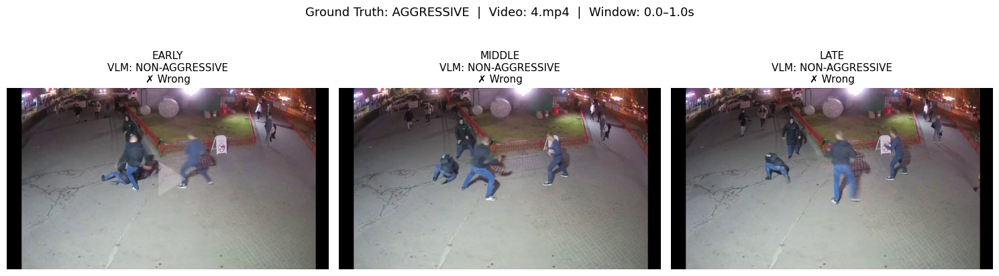

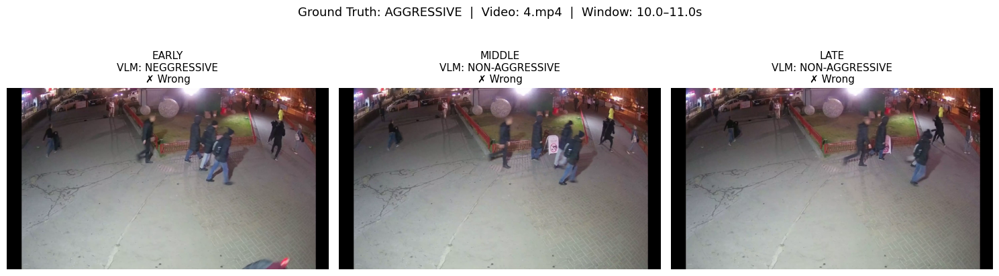

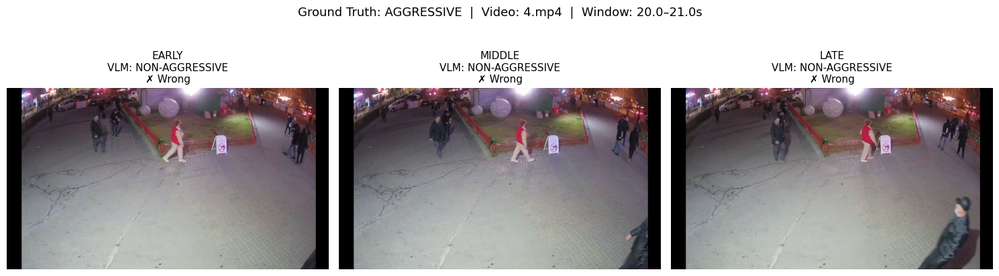

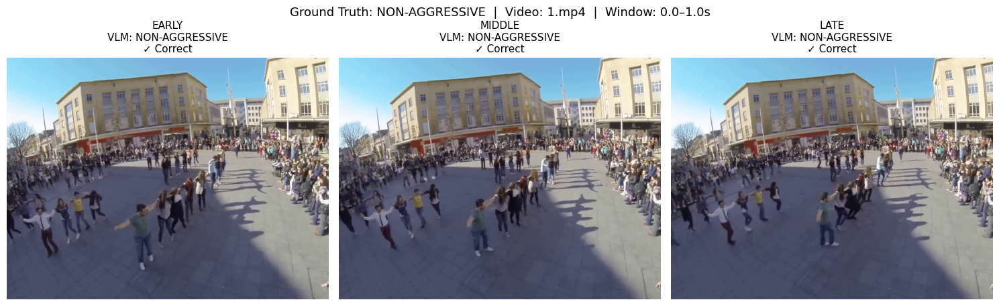

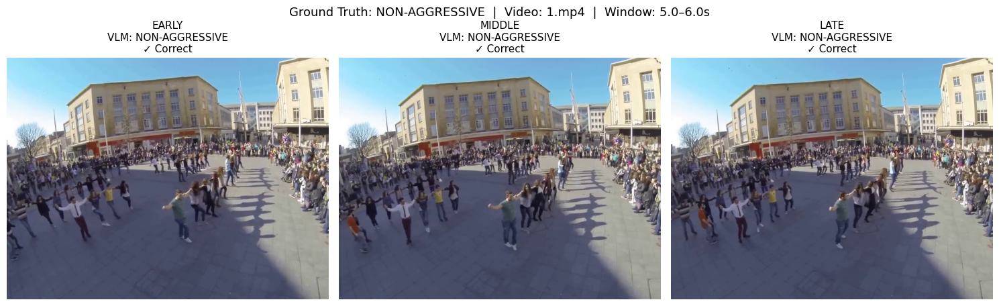

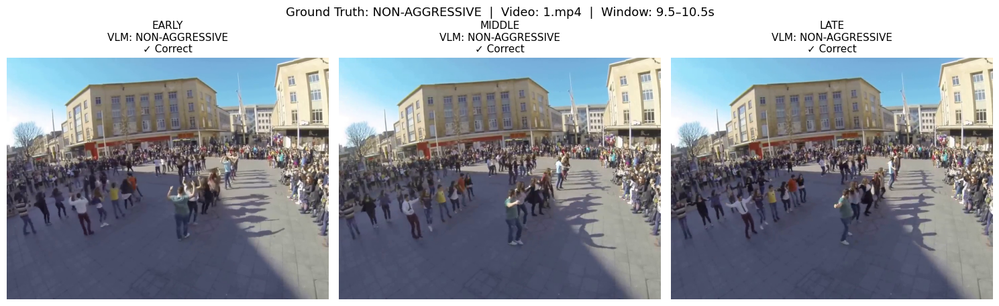

In [97]:
vlm_visual_results = run_and_visualize_vlm_samples(
    selected_windows,
    max_samples=6
)

### Observations
1. VLm also fials to predict aggressive cases by looking at single frame

### VLM performance on temporal setting

In [98]:
SEQUENCE_CLASS_PROMPT = """
You are given a sequence of video frames in chronological order.

Classify the overall activity shown in the sequence as exactly one of:

AGGRESSIVE
NON-AGGRESSIVE

Use the visual information across all frames.
Consider changes and actions across the sequence, not just one frame.

Reply with only:
AGGRESSIVE
or
NON-AGGRESSIVE
"""

In [101]:
from PIL import Image
import torch

def run_vlm_sequence_8(frames, prompt, max_new_tokens=10):

    # Select 8 uniformly distributed frames
    indices = np.linspace(
        0,
        len(frames) - 1,
        8
    ).astype(int)

    selected_frames = [
        frames[i] for i in indices
    ]

    images = [
        Image.fromarray(frame).convert("RGB")
        for frame in selected_frames
    ]

    # Create multimodal input
    content = []

    for _ in images:
        content.append({"type": "image"})

    content.append({
        "type": "text",
        "text": prompt
    })

    messages = [
        {
            "role": "user",
            "content": content
        }
    ]

    text = vlm_processor.apply_chat_template(
        messages,
        add_generation_prompt=True,
        tokenize=False
    )

    inputs = vlm_processor(
        text=text,
        images=images,
        return_tensors="pt"
    )

    inputs = {
        k: v.to(vlm_model.device) if hasattr(v, "to") else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        output_ids = vlm_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    input_length = inputs["input_ids"].shape[1]

    generated_ids = output_ids[:, input_length:]

    response = vlm_processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0].strip()

    return response

In [102]:
test_window = test_windows[0]

prediction = run_vlm_sequence_8(
    test_window["frames"],
    SEQUENCE_CLASS_PROMPT
)

ground_truth = (
    "AGGRESSIVE"
    if test_window["label"] == 1
    else "NON-AGGRESSIVE"
)

print("Ground Truth :", ground_truth)
print("VLM Prediction:", prediction)

Ground Truth : AGGRESSIVE
VLM Prediction: NON-AGGRESSIVE.


In [104]:
vlm_sequence_results = []

for i, window in enumerate(test_windows):

    print(
        f"{i+1}/{len(test_windows)} | "
        f"{window['source_video']} | "
        f"{window['start_time']:.1f}-"
        f"{window['end_time']:.1f}s"
    )

    prediction = run_vlm_sequence_8(
        window["frames"],
        SEQUENCE_CLASS_PROMPT
    )

    ground_truth = (
        "AGGRESSIVE"
        if window["label"] == 1
        else "NON-AGGRESSIVE"
    )

    pred_clean = (
        prediction
        .upper()
        .replace(".", "")
        .strip()
    )

    if "NON-AGGRESSIVE" in pred_clean:
        pred_clean = "NON-AGGRESSIVE"
    elif "AGGRESSIVE" in pred_clean:
        pred_clean = "AGGRESSIVE"

    vlm_sequence_results.append({
        "source_video": window["source_video"],
        "window_id": window["window_id"],
        "start_time": window["start_time"],
        "end_time": window["end_time"],
        "ground_truth": ground_truth,
        "prediction": pred_clean,
        "correct": pred_clean == ground_truth
    })

1/61 | 4.mp4 | 0.0-1.0s
2/61 | 4.mp4 | 0.5-1.5s
3/61 | 4.mp4 | 1.0-2.0s
4/61 | 4.mp4 | 1.5-2.5s
5/61 | 4.mp4 | 2.0-3.0s
6/61 | 4.mp4 | 2.5-3.5s
7/61 | 4.mp4 | 3.0-4.0s
8/61 | 4.mp4 | 3.5-4.5s
9/61 | 4.mp4 | 4.0-5.0s
10/61 | 4.mp4 | 4.5-5.5s
11/61 | 4.mp4 | 5.0-6.0s
12/61 | 4.mp4 | 5.5-6.5s
13/61 | 4.mp4 | 6.0-7.0s
14/61 | 4.mp4 | 6.5-7.5s
15/61 | 4.mp4 | 7.0-8.0s
16/61 | 4.mp4 | 7.5-8.5s
17/61 | 4.mp4 | 8.0-9.0s
18/61 | 4.mp4 | 8.5-9.5s
19/61 | 4.mp4 | 9.0-10.0s
20/61 | 4.mp4 | 9.5-10.5s
21/61 | 4.mp4 | 10.0-11.0s
22/61 | 4.mp4 | 10.5-11.5s
23/61 | 4.mp4 | 11.0-12.0s
24/61 | 4.mp4 | 11.5-12.5s
25/61 | 4.mp4 | 12.0-13.0s
26/61 | 4.mp4 | 12.5-13.5s
27/61 | 4.mp4 | 13.0-14.0s
28/61 | 4.mp4 | 13.5-14.5s
29/61 | 4.mp4 | 14.0-15.0s
30/61 | 4.mp4 | 14.5-15.5s
31/61 | 4.mp4 | 15.0-16.0s
32/61 | 4.mp4 | 15.5-16.5s
33/61 | 4.mp4 | 16.0-17.0s
34/61 | 4.mp4 | 16.5-17.5s
35/61 | 4.mp4 | 17.0-18.0s
36/61 | 4.mp4 | 17.5-18.5s
37/61 | 4.mp4 | 18.0-19.0s
38/61 | 4.mp4 | 18.5-19.5s
39/61 | 4.mp4 | 19.0-

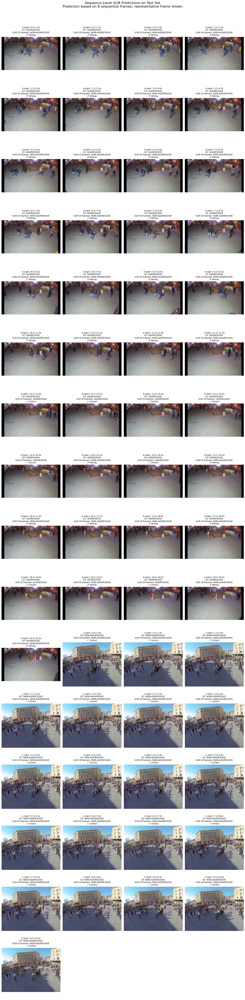

In [105]:
import matplotlib.pyplot as plt
import math

# Number of clips to display
n = len(test_windows)

# Grid size
cols = 4
rows = math.ceil(n / cols)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(16, rows * 4)
)

axes = np.array(axes).reshape(-1)

for i, (ax, window, result) in enumerate(
    zip(axes, test_windows, vlm_sequence_results)
):

    # Show ONE representative frame
    # Middle frame of the original 16-frame window
    frame = window["frames"][8]

    ax.imshow(frame)
    ax.axis("off")

    gt = result["ground_truth"]
    pred = result["prediction"]

    correct = result["correct"]

    status = "✓ Correct" if correct else "✗ Wrong"

    ax.set_title(
        f"{window['source_video']} | "
        f"{window['start_time']:.1f}–{window['end_time']:.1f}s\n"
        f"GT: {gt}\n"
        f"VLM (8 frames): {pred}\n"
        f"{status}",
        fontsize=10
    )

# Hide unused axes
for ax in axes[n:]:
    ax.axis("off")

fig.suptitle(
    "Sequence-Level VLM Predictions on Test Set\n"
    "Prediction based on 8 sequential frames; representative frame shown",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

### observations
1. After processing sequence level frames as well VLM is still confused on aggresive clips

### Research analysis